# Task 1 - Time-Series Preprocessing, Exploratory Analysis and Forecasting
## Hourly Traffic Volume on Interstate 94 (Minneapolis - St Paul)

**Course:** Time-Series Pipeline (group assignment) | **Notebook scope:** Task 1 (A. Understanding the data, B. Analytical questions, C. Model training)

### Problem definition
Traffic agencies need to know how many vehicles will use a road in the next hour so they can time signals, schedule maintenance and warn drivers. We treat this as a **supervised time-series forecasting (regression) problem**:

> *Given the traffic history up to hour t-1 and the weather / calendar information for hour t, predict the westbound traffic volume (vehicles per hour) at hour t.*

### Why this dataset
| Assignment requirement | How the **Metro Interstate Traffic Volume** dataset meets it |
|---|---|
| Clear timestamp | `date_time`, hourly, Oct 2012 - Sep 2018 |
| Meaningful target | `traffic_volume` (vehicles/hour) - a continuous forecasting target |
| Multiple measurable variables | temperature, rain, snow, cloud cover, weather type, holidays |
| Real-world data problems | duplicated timestamps, a ~10-month hole in the series, sensor outliers - so preprocessing decisions genuinely matter |
| Domain relevance | transportation planning, congestion management |

**Source:** UCI Machine Learning Repository, *Metro Interstate Traffic Volume* (CC BY 4.0), MN DoT ATR station 301 (westbound I-94).

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from preprocessing import (load_raw, clean, add_features, TARGET, TEMP_MIN_K, RAIN_MAX_MM,
                           MAX_INTERP_HOURS, LAGS, ROLL_WINDOWS, ALL_FEATURES, WEATHER_FEATURES,
                           CALENDAR_FEATURES, LAG_FEATURES)

FIG = ROOT / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
def save(name): plt.savefig(FIG / f"{name}.png", dpi=140, bbox_inches="tight")
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

# Part A - Understanding the dataset

### A1. Structure of the raw data

In [2]:
raw = load_raw(ROOT / "data" / "raw" / "Metro_Interstate_Traffic_Volume.csv")
print("Shape:", raw.shape)
display(raw.head())
raw.info()

Shape: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   holiday              61 non-null     str           
 1   temp                 48204 non-null  float64       
 2   rain_1h              48204 non-null  float64       
 3   snow_1h              48204 non-null  float64       
 4   clouds_all           48204 non-null  int64         
 5   weather_main         48204 non-null  str           
 6   weather_description  48204 non-null  str           
 7   date_time            48204 non-null  datetime64[us]
 8   traffic_volume       48204 non-null  int64         
dtypes: datetime64[us](1), float64(3), int64(2), str(3)
memory usage: 3.3 MB


### A2. Time range and frequency

In [3]:
ts = raw["date_time"]
unique_ts = ts.drop_duplicates().sort_values()
print("Start :", ts.min())
print("End   :", ts.max())
print("Span  :", ts.max() - ts.min())
print()
print("Most common spacing between consecutive unique timestamps:")
print(unique_ts.diff().dropna().value_counts().head(6))

expected = pd.date_range(ts.min(), ts.max(), freq="h")
print(f"\nRows in file               : {len(raw):,}")
print(f"Unique timestamps          : {unique_ts.size:,}")
print(f"Hours expected in the span : {len(expected):,}")
print(f"Hours with NO record       : {len(expected) - unique_ts.size:,}  ({(len(expected)-unique_ts.size)/len(expected):.1%})")
print(f"Rows sharing a timestamp   : {ts.duplicated().sum():,}  (fully identical rows: {raw.duplicated().sum()})")

# do duplicated timestamps disagree about the target?
n_diff = (raw.groupby("date_time")[TARGET].nunique() > 1).sum()
print(f"Timestamps whose duplicate rows have DIFFERENT traffic_volume: {n_diff}")

Start : 2012-10-02 09:00:00
End   : 2018-09-30 23:00:00
Span  : 2189 days 14:00:00

Most common spacing between consecutive unique timestamps:
date_time
0 days 01:00:00    37986
0 days 02:00:00     2192
0 days 03:00:00      201
0 days 04:00:00       59
0 days 05:00:00       33
0 days 06:00:00       17
Name: count, dtype: int64

Rows in file               : 48,204
Unique timestamps          : 40,575
Hours expected in the span : 52,551
Hours with NO record       : 11,976  (22.8%)
Rows sharing a timestamp   : 7,629  (fully identical rows: 17)
Timestamps whose duplicate rows have DIFFERENT traffic_volume: 0


**Findings.** The data is **hourly** (the dominant spacing is exactly 1 hour), covering **2 Oct 2012 - 30 Sep 2018**. Two irregularities appear: (1) many timestamps are repeated - the repeats carry the *same* traffic volume but a different `weather_description`, i.e. the file has one row per weather report rather than one per hour; (2) a large number of hours have no record at all, so the series is **not** a regular hourly grid.

### A3. Missing values

In [4]:
print("Explicit missing values (NaN) per column:")
print(raw.isna().sum().to_string())
print(f"\n`holiday` is NaN on {raw.holiday.isna().mean():.1%} of rows: NaN simply means 'not a holiday'.")
print(raw.holiday.value_counts().to_string())

Explicit missing values (NaN) per column:
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0

`holiday` is NaN on 99.9% of rows: NaN simply means 'not a holiday'.
holiday
Labor Day                    7
Thanksgiving Day             6
Christmas Day                6
New Years Day                6
Martin Luther King Jr Day    6
Columbus Day                 5
Veterans Day                 5
Washingtons Birthday         5
Memorial Day                 5
Independence Day             5
State Fair                   5


Apart from `holiday` (where NaN means *no holiday*) the file contains no explicit NaNs. The real missing-data problem is **implicit**: whole hours are absent. We quantify it by comparing against a complete hourly calendar.

,n_gaps,total_hours_missing
hours,,
1 h,2192,2192
2-3 h,260,579
4-6 h,60,277
7-24 h,65,742
2-7 days,9,558
> 7 days,2,7628


Five longest gaps:


,start,end,hours
896,2014-08-08 02:00:00,2015-06-11 19:00:00,7386
664,2013-10-27 02:00:00,2013-11-06 03:00:00,242
902,2015-06-14 21:00:00,2015-06-19 17:00:00,117
783,2014-04-29 09:00:00,2014-05-04 04:00:00,116
1024,2015-10-23 12:00:00,2015-10-27 07:00:00,92


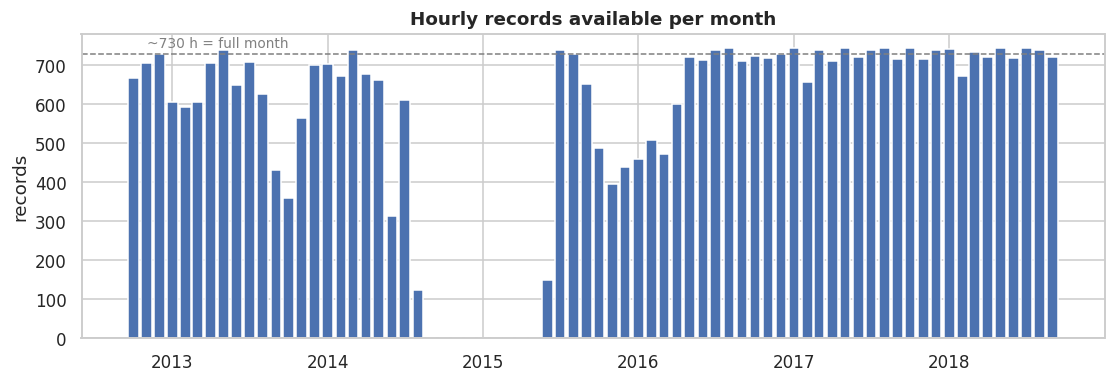

In [5]:
missing = expected.difference(unique_ts)
m = pd.Series(missing)
gap_id = (m.diff() != pd.Timedelta("1h")).cumsum()
gaps = m.groupby(gap_id.values).agg(start="min", end="max", hours="count")
bins = pd.cut(gaps.hours, [0, 1, 3, 6, 24, 168, np.inf],
              labels=["1 h", "2-3 h", "4-6 h", "7-24 h", "2-7 days", "> 7 days"])
summary = gaps.groupby(bins, observed=False).agg(n_gaps=("hours", "size"), total_hours_missing=("hours", "sum"))
display(summary)
print("Five longest gaps:")
display(gaps.sort_values("hours", ascending=False).head(5))

monthly = unique_ts.dt.to_period("M").value_counts().sort_index()
monthly.index = monthly.index.to_timestamp()
monthly = monthly.reindex(pd.date_range(monthly.index.min(), monthly.index.max(), freq="MS"), fill_value=0)
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.bar(monthly.index, monthly.values, width=25, color=sns.color_palette()[0])
ax.axhline(730, ls="--", c="grey", lw=1); ax.text(monthly.index[1], 745, "~730 h = full month", color="grey", fontsize=9)
ax.set(title="Hourly records available per month", ylabel="records")
save("a_records_per_month"); plt.show()

**Interpretation.** 11,976 of the 52,551 hours in the span (**22.8%**) have no record, so the series is far from regular. The gaps fall into two very different groups:

* **Short gaps** - 2,512 gaps of 1-6 hours (3,048 missing hours in total, 25% of everything missing). These look like ordinary logging dropouts and are safe to bridge.
* **Long gaps** - one outage from **8 Aug 2014 to 11 Jun 2015 (7,386 hours, about 10 months)** accounts for 62% of all missing hours, and ten other outages of two days or longer exist (the longest, about 10 days, in Oct-Nov 2013). The monthly bar chart shows 2014-15 almost empty.

The missingness is therefore *blocked*, not random. That rules out a single global strategy: interpolating a 10-month hole would invent seasonality, whereas deleting every short gap would break the hour-by-hour structure that lag features rely on. This is why we use the two-tier approach in A5.

### A4. Outliers and sensor errors

In [6]:
bad_temp = raw[raw.temp < TEMP_MIN_K]
print(f"temp < {TEMP_MIN_K} K (physically impossible): {len(bad_temp)} rows, dates: {sorted(bad_temp.date_time.dt.date.astype(str).unique())}")
print("\nLargest rain_1h values (mm in one hour):")
display(raw.nlargest(4, "rain_1h")[["date_time", "rain_1h", "weather_main", "traffic_volume"]])
print("Hours with traffic_volume == 0:", (raw.traffic_volume == 0).sum())

temp < 200 K (physically impossible): 10 rows, dates: ['2014-01-31', '2014-02-02']

Largest rain_1h values (mm in one hour):


,date_time,rain_1h,weather_main,traffic_volume
24872,2016-07-11 17:00:00,9831.30,Rain,5535
8247,2013-08-07 02:00:00,55.63,Rain,315
7179,2013-06-24 11:00:00,44.45,Rain,4802
25779,2016-08-16 17:00:00,31.75,Rain,4913


Hours with traffic_volume == 0: 2


A temperature of 0 K (-273 degC) is impossible, and 9,831 mm of rain in one hour (about 10 metres) is a sensor fault; the next-largest reading is under 60 mm. Both are clear errors rather than extreme-but-real values.

### A5. Handling missing values and errors - methods and justification
All cleaning is implemented in `src/preprocessing.py::clean()` so that the **identical pipeline** can be re-used in Task 4.

| Problem | Treatment | Why this method |
|---|---|---|
| Repeated timestamps | Group by timestamp: **mean** of numeric columns, first weather label | Duplicates carry identical traffic values (verified above), so aggregating loses nothing and gives one row per hour |
| Impossible values (temp = 0 K, rain > 100 mm) | Set to **NaN**, then treat as missing | Deleting the row would also delete a valid traffic reading; marking as NaN keeps the traffic value |
| Missing hours | Re-index to a **complete hourly grid** so gaps become explicit | Lag and rolling features are only correct if "t-24" really means 24 hours earlier |
| Short gaps (<= 6 h) | **Time-based linear interpolation** | Traffic and weather change smoothly over a few hours, so interpolation is a defensible estimate |
| Long gaps (> 6 h, incl. the ~10-month hole) | **Left as NaN** and the affected rows dropped when building features | Interpolating days or months would fabricate the daily/weekly pattern we are trying to model and would bias every result |
| `holiday` NaN | Converted to a 0/1 `is_holiday` flag for the **whole calendar day** | The raw file marks holidays only on the first hour of the day |
| Imputed rows | Flagged with `observed = False` | Models are *trained and evaluated on real readings only* |

                           hours
Hourly grid length         52551
Real observations          40575
Interpolated (short gaps)   3048
Still missing (long gaps)   8928


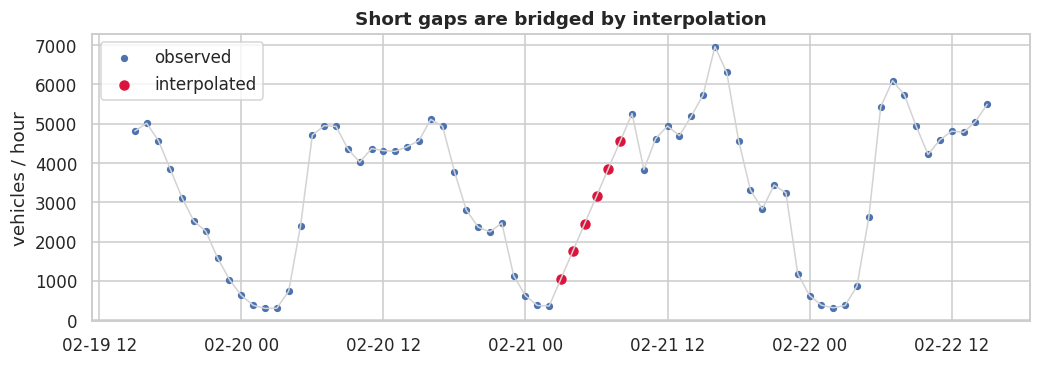

In [7]:
clean_df = clean(raw)
n_obs = int(clean_df.observed.sum())
n_imp = int((~clean_df.observed & clean_df[TARGET].notna()).sum())
n_left = int(clean_df[TARGET].isna().sum())
print(pd.DataFrame({"hours": [len(clean_df), n_obs, n_imp, n_left]},
                   index=["Hourly grid length", "Real observations", "Interpolated (short gaps)", "Still missing (long gaps)"]))
assert clean_df.index.is_unique and clean_df.index.to_series().diff().dropna().eq(pd.Timedelta("1h")).all()

# visual check of what interpolation does
imp_times = clean_df.index[~clean_df.observed & clean_df[TARGET].notna()]
t0 = imp_times[imp_times >= "2017-01-01"][0]
w = clean_df.loc[t0 - pd.Timedelta("36h"): t0 + pd.Timedelta("36h")]
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(w.index, w[TARGET], c="lightgrey", lw=1)
ax.scatter(w.index[w.observed], w[TARGET][w.observed], s=14, label="observed")
ax.scatter(w.index[~w.observed], w[TARGET][~w.observed], s=34, c="crimson", label="interpolated")
ax.set(title="Short gaps are bridged by interpolation", ylabel="vehicles / hour"); ax.legend()
save("a_interpolation_example"); plt.show()

### A6. Statistical distribution of the numerical columns

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
temp,40575.0,281.38,13.10,243.39,271.84,282.86,292.28,310.07,-0.38,-0.69
rain_1h,40575.0,0.08,0.77,0.00,0.00,0.00,0.00,55.63,28.65,1321.85
snow_1h,40575.0,0.00,0.01,0.00,0.00,0.00,0.00,0.51,65.91,4968.37
clouds_all,40575.0,44.20,38.68,0.00,1.00,40.00,90.00,100.00,0.03,-1.76
traffic_volume,40575.0,3290.65,1984.77,0.00,1248.50,3427.00,4952.00,7280.00,-0.11,-1.30


Share of hours with zero rain: 94.9% | zero snow: 99.92%


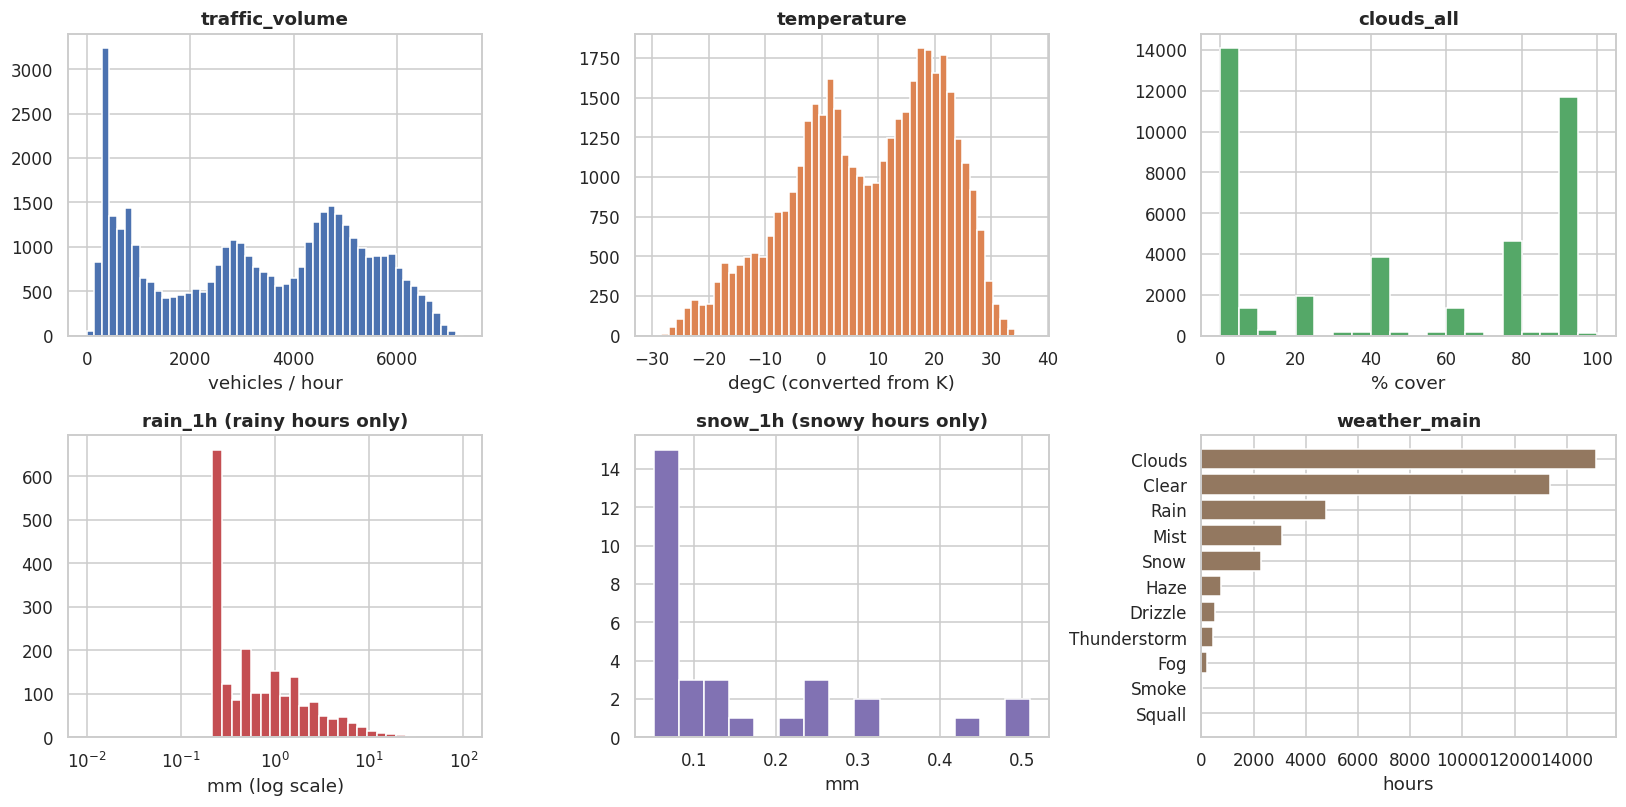

In [8]:
obs = clean_df[clean_df.observed].copy()          # real readings only
num = ["temp", "rain_1h", "snow_1h", "clouds_all", TARGET]
desc = obs[num].describe().T
desc["skew"] = obs[num].skew(); desc["kurtosis"] = obs[num].kurt()
display(desc.round(2))
print(f"Share of hours with zero rain: {(obs.rain_1h == 0).mean():.1%} | zero snow: {(obs.snow_1h == 0).mean():.2%}")

fig, axs = plt.subplots(2, 3, figsize=(15, 7.5))
axs[0, 0].hist(obs[TARGET], bins=50, color=sns.color_palette()[0]); axs[0, 0].set(title="traffic_volume", xlabel="vehicles / hour")
axs[0, 1].hist(obs.temp - 273.15, bins=50, color=sns.color_palette()[1]); axs[0, 1].set(title="temperature", xlabel="degC (converted from K)")
axs[0, 2].hist(obs.clouds_all, bins=20, color=sns.color_palette()[2]); axs[0, 2].set(title="clouds_all", xlabel="% cover")
axs[1, 0].hist(obs.rain_1h[obs.rain_1h > 0], bins=np.logspace(-2, 2, 40), color=sns.color_palette()[3]); axs[1, 0].set_xscale("log"); axs[1, 0].set(title="rain_1h (rainy hours only)", xlabel="mm (log scale)")
axs[1, 1].hist(obs.snow_1h[obs.snow_1h > 0], bins=15, color=sns.color_palette()[4]); axs[1, 1].set(title="snow_1h (snowy hours only)", xlabel="mm")
wc = obs.weather_main.value_counts()
axs[1, 2].barh(wc.index[::-1], wc.values[::-1], color=sns.color_palette()[5]); axs[1, 2].set(title="weather_main", xlabel="hours")
plt.tight_layout(); save("a_distributions"); plt.show()

**Interpretation.**

* **traffic_volume** (mean 3,291, median 3,427, SD 1,985, range 0-7,280) is not bell-shaped: its kurtosis of -1.3 and the histogram show **several modes** - a spike near 300-400 vehicles (overnight), a shoulder around 2,800-3,000 and the main peak near 4,800 (daytime). The mixture reflects the hour-of-day cycle explored in Q2, which is why a model needs time-of-day information. Skewness is only -0.11, so no target transformation is needed.
* **temperature** (mean about 8 degC, range -30 to +37 degC) is **bimodal** - a winter cluster near 0 degC and a summer cluster near 20 degC - the signature of Minnesota's strong seasonality.
* **rain_1h**: 94.9% of hours are dry; the rest is extremely right-skewed (skew 28.7). Most non-zero readings sit at the sensor's smallest step (about 0.25 mm).
* **snow_1h**: only about 30 hours (0.08%) have a non-zero value, even though 2,297 hours are labelled "Snow" in `weather_main`. `snow_1h` is therefore close to uninformative, and `weather_main` is the better snow indicator.
* **clouds_all** is reported in coarse steps (0, 20, 40, 75, 90 %), giving a spiky histogram.
* **weather_main** is dominated by Clouds and Clear; *Squall* (1 hour) and *Smoke* (15 hours) are almost empty, so their one-hot columns will rarely fire.

Because we plan tree-based models, the heavy skew in rain and snow does not require transformation.

# Part B - Analytical questions

## Q1. Does traffic volume show a long-term increasing or decreasing trend?
*Method:* monthly mean traffic (months with >= 500 real hourly readings), plus a linear regression of the monthly mean on time and yearly averages.

Months used: 53 | slope = +1.14 vehicles/h per month (+13.7 per year) | R2 = 0.025 | p = 0.258


,mean,count
date_time,,
2012,3227.0,2103
2013,3310.0,7294
2014,3270.0,4501
2015,3258.0,3593
2016,3194.0,7838
2017,3377.0,8713
2018,3324.0,6533


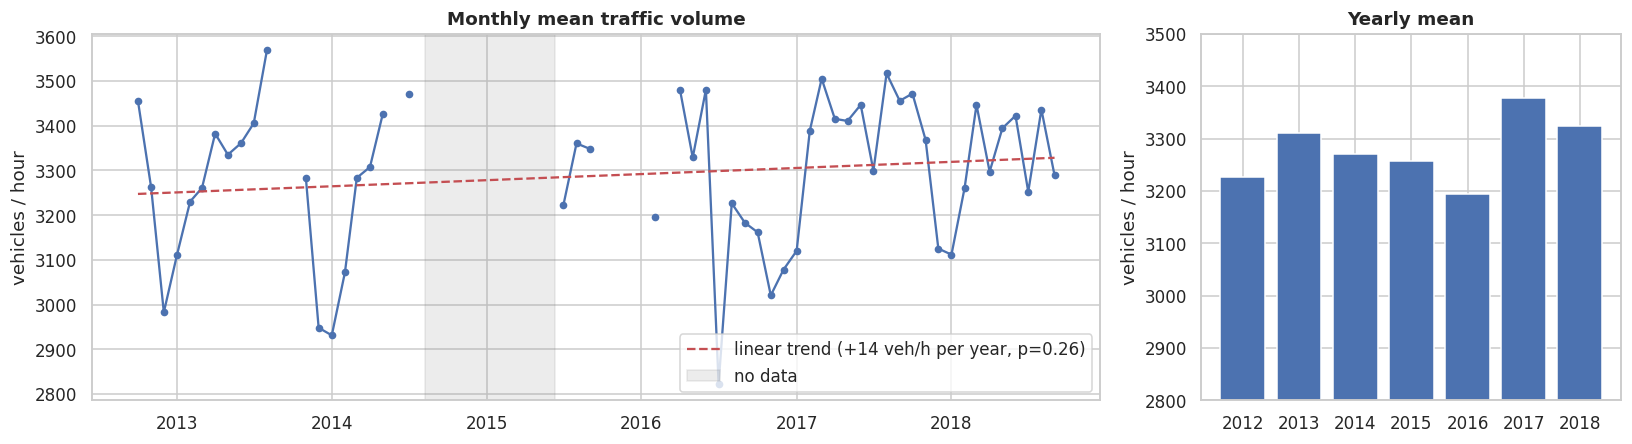

In [9]:
mm = obs[TARGET].resample("MS").agg(["mean", "count"])
mm = mm[mm["count"] >= 500]
xm = mm.index.year * 12 + mm.index.month              # true month number (gaps keep their spacing)
lr = stats.linregress(xm, mm["mean"])
print(f"Months used: {len(mm)} | slope = {lr.slope:+.2f} vehicles/h per month ({lr.slope*12:+.1f} per year) | R2 = {lr.rvalue**2:.3f} | p = {lr.pvalue:.3f}")
yearly = obs.groupby(obs.index.year)[TARGET].agg(["mean", "count"]).round(0)
display(yearly)

full = mm["mean"].reindex(pd.date_range(mm.index.min(), mm.index.max(), freq="MS"))
fig, axs = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [2.4, 1]})
axs[0].plot(full.index, full.values, marker="o", ms=4)
fit = lr.intercept + lr.slope * (full.index.year * 12 + full.index.month)
axs[0].plot(full.index, fit, "r--", label=f"linear trend ({lr.slope*12:+.0f} veh/h per year, p={lr.pvalue:.2f})")
axs[0].axvspan(pd.Timestamp("2014-08-08"), pd.Timestamp("2015-06-11"), color="grey", alpha=.15, label="no data")
axs[0].set(title="Monthly mean traffic volume", ylabel="vehicles / hour"); axs[0].legend()
axs[1].bar(yearly.index.astype(str), yearly["mean"], color=sns.color_palette()[0]); axs[1].set(title="Yearly mean", ylabel="vehicles / hour")
axs[1].set_ylim(2800, 3500)
plt.tight_layout(); save("q1_trend"); plt.show()

**Interpretation.** There is **no meaningful long-term trend**. The fitted slope is only +1.1 vehicles/hour per month (about +14 per year, roughly 0.4% of the average level), with R2 = 0.025 and p = 0.26 - not statistically distinguishable from zero. Yearly means move within about +-3% of 3,290 (lowest 3,194 in 2016, highest 3,377 in 2017) with no consistent direction. One caveat: the years do not cover the same months (2012 has only Oct-Dec, 2014-15 are patchy), so yearly averages are partly shaped by which seasons are present - the monthly regression reduces but does not eliminate this effect.

**Implication:** the level of the series is effectively stationary, so we do not need de-trending or a "year" feature (which would also extrapolate badly). The variation that matters is *within* days and weeks (Q2).

## Q2. What are the daily and weekly seasonal patterns?
*Method:* average traffic by hour of day for weekdays vs weekends, and a day-of-week x hour heat-map.

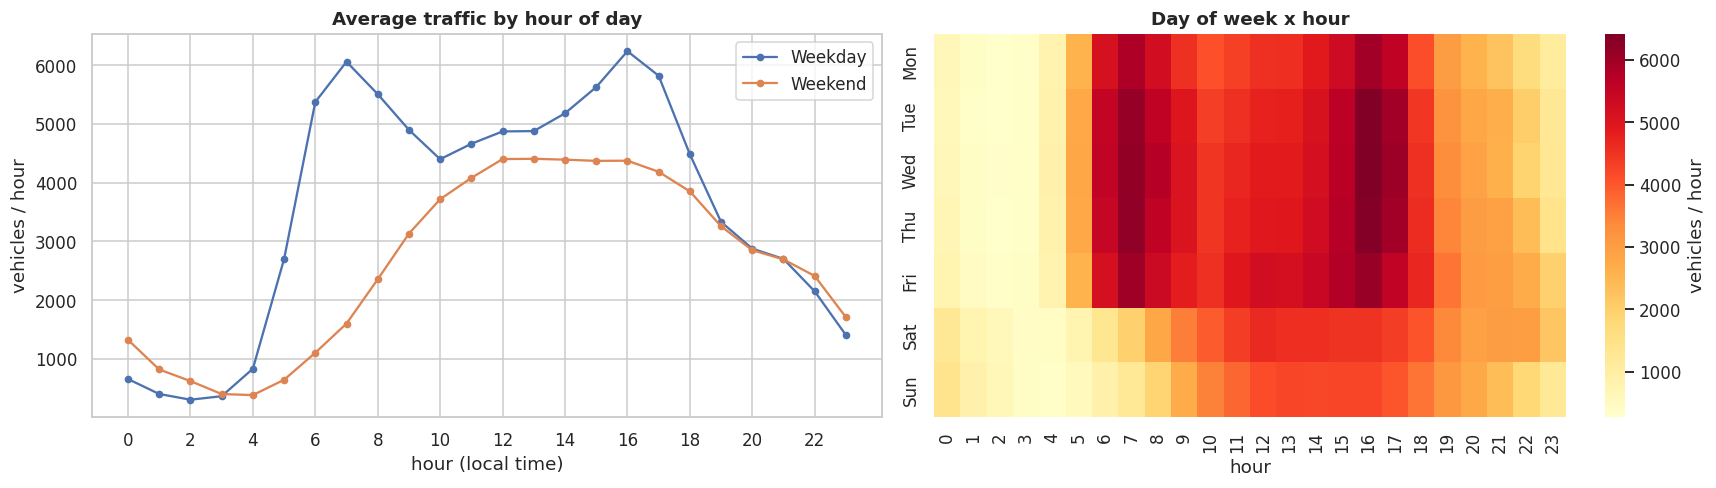

Overall peak hour 16:00 (5,709) | trough 3:00 (373)
Weekday mean 3,572 vs weekend mean 2,629
Weekday peaks: {16: 6241.0, 7: 6061.0, 17: 5823.0}
Weekend peaks: {13: 4408.0, 12: 4403.0, 14: 4393.0}
Mean by day of week: {'Mon': 3314.0, 'Tue': 3535.0, 'Wed': 3608.0, 'Thu': 3654.0, 'Fri': 3675.0, 'Sat': 2823.0, 'Sun': 2426.0}
Weekend vs weekday overall: -26.2%


In [10]:
is_we = np.where(obs.index.dayofweek >= 5, "Weekend", "Weekday")
prof = obs.groupby([obs.index.hour, is_we])[TARGET].mean().unstack()
heat = obs.pivot_table(index=obs.index.dayofweek, columns=obs.index.hour, values=TARGET, aggfunc="mean")
heat.index = DAYS
dow_mean = obs.groupby(obs.index.dayofweek)[TARGET].mean(); dow_mean.index = DAYS

fig, axs = plt.subplots(1, 2, figsize=(16, 4.6))
prof.plot(ax=axs[0], marker="o", ms=4); axs[0].set(title="Average traffic by hour of day", xlabel="hour (local time)", ylabel="vehicles / hour", xticks=range(0, 24, 2))
sns.heatmap(heat, cmap="YlOrRd", ax=axs[1], cbar_kws={"label": "vehicles / hour"}); axs[1].set(title="Day of week x hour", xlabel="hour", ylabel="")
plt.tight_layout(); save("q2_seasonality"); plt.show()

hr = obs.groupby(obs.index.hour)[TARGET].mean()
print(f"Overall peak hour {hr.idxmax()}:00 ({hr.max():,.0f}) | trough {hr.idxmin()}:00 ({hr.min():,.0f})")
print(f"Weekday mean {prof['Weekday'].mean():,.0f} vs weekend mean {prof['Weekend'].mean():,.0f}")
print("Weekday peaks:", prof['Weekday'].nlargest(3).round(0).to_dict())
print("Weekend peaks:", prof['Weekend'].nlargest(3).round(0).to_dict())
print("Mean by day of week:", dow_mean.round(0).to_dict())
print(f"Weekend vs weekday overall: {(obs[is_we=='Weekend'][TARGET].mean()/obs[is_we=='Weekday'][TARGET].mean()-1):+.1%}")

**Interpretation.** Traffic is dominated by a strong daily and weekly rhythm.

* **Daily:** the road is nearly empty at night (trough 373 vehicles/hour at 03:00), ramps up sharply between 05:00 and 07:00 and peaks at 16:00 (5,709 on average across all days).
* **Weekdays vs weekends:** weekdays show two **rush-hour peaks** (07:00 at about 6,061 and 16:00 at about 6,241), whereas weekends have a single, lower **midday plateau** peaking at 12:00-14:00 (about 4,400). Weekend traffic is **26% lower** overall (2,629 vs 3,572).
* **Day of week:** Monday is the quietest weekday (3,314) and Friday the busiest (3,675); Sunday is the quietest day of the week (2,426).

**Implication:** hour-of-day and day-of-week *interact* (the shape of the day changes at weekends), so the model needs both. We encode them cyclically (sin/cos) and include a weekend flag; tree models can learn the interaction directly.

## Q3. Do weather variables correlate with traffic volume?
*Method:* (a) plain correlations; (b) because weather and time-of-day are entangled (fog is mostly an early-morning phenomenon, when traffic is low anyway), we also measure the **excess traffic** = actual - typical traffic for that weekday-and-hour, and relate *that* to weather.

,corr with traffic,corr with excess traffic
temp,0.140,0.168
clouds_all,0.078,-0.075
rain_1h,-0.013,-0.031
snow_1h,-0.002,-0.016


Spearman (rank) correlation with traffic: {'temp': 0.14, 'clouds_all': 0.073, 'rain_1h': 0.004, 'snow_1h': -0.005}


,n,mean_traffic,mean_excess
weather_main,,,
Snow,2297,3002.0,-280.0
Haze,766,3598.0,-55.0
Thunderstorm,453,2993.0,-17.0
Mist,3069,2854.0,-1.0
Rain,4769,3355.0,-1.0
Clouds,15123,3617.0,16.0
Clear,13366,3055.0,32.0
Drizzle,515,3160.0,46.0
Fog,201,2724.0,61.0


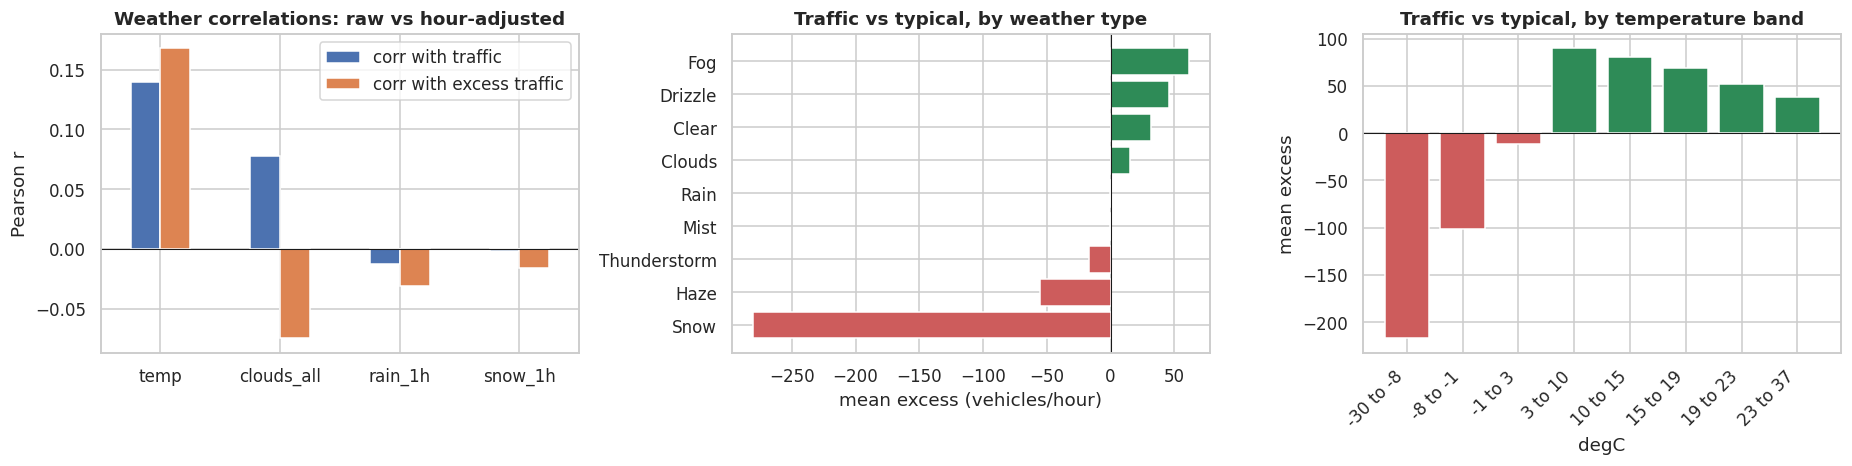

In [11]:
typical = obs.groupby([obs.index.dayofweek, obs.index.hour])[TARGET].transform("mean")
obs["typical"] = typical
obs["excess"] = obs[TARGET] - typical
wcols = ["temp", "clouds_all", "rain_1h", "snow_1h"]
raw_corr = obs[wcols].corrwith(obs[TARGET])
adj_corr = obs[wcols].corrwith(obs["excess"])
cmp_ = pd.DataFrame({"corr with traffic": raw_corr, "corr with excess traffic": adj_corr}).round(3)
display(cmp_)
print("Spearman (rank) correlation with traffic:", obs[wcols].corrwith(obs[TARGET], method="spearman").round(3).to_dict())

wx = obs.groupby("weather_main").agg(n=(TARGET, "size"), mean_traffic=(TARGET, "mean"), mean_excess=("excess", "mean"))
wx = wx[wx.n >= 200].sort_values("mean_excess")
display(wx.round(0))
tb = pd.qcut(obs.temp - 273.15, 8)
tx = obs.groupby(tb, observed=True)["excess"].mean()

fig, axs = plt.subplots(1, 3, figsize=(17, 4.4))
cmp_.plot.bar(ax=axs[0], rot=0); axs[0].set(title="Weather correlations: raw vs hour-adjusted", ylabel="Pearson r"); axs[0].axhline(0, c="k", lw=.7)
axs[1].barh(wx.index, wx.mean_excess, color=np.where(wx.mean_excess > 0, "seagreen", "indianred")); axs[1].axvline(0, c="k", lw=.7)
axs[1].set(title="Traffic vs typical, by weather type", xlabel="mean excess (vehicles/hour)")
axs[2].bar(range(len(tx)), tx.values, color=np.where(tx.values > 0, "seagreen", "indianred")); axs[2].set_xticks(range(len(tx)))
axs[2].set_xticklabels([f"{i.left:.0f} to {i.right:.0f}" for i in tx.index], rotation=45, ha="right"); axs[2].axhline(0, c="k", lw=.7)
axs[2].set(title="Traffic vs typical, by temperature band", xlabel="degC", ylabel="mean excess")
plt.tight_layout(); save("q3_weather"); plt.show()

**Interpretation.** Weather is a **weak** driver compared with the calendar.

* Raw correlations with traffic are tiny: temperature +0.14, cloud cover +0.08, rain -0.01, snow -0.00.
* The raw weather-type averages look dramatic (Clouds 3,617 vs Fog 2,724 vehicles/hour), but this is largely **confounding with time of day**: fog and mist occur mostly in the early morning when traffic is low anyway. After subtracting the typical traffic for that weekday and hour, Fog, Drizzle, Clear and Clouds are all within about +-60 vehicles/hour of normal, and Rain and Mist are essentially zero.
* Two effects survive the adjustment. **Snow** hours run about **280 vehicles/hour below typical**, and **temperature** has a *non-linear* effect: below -8 degC traffic is about 215 vehicles/hour under normal and between -8 and -1 degC about 100 under; from +3 degC upward it is slightly above normal (+40 to +90). Even so, temperature correlates only +0.17 with the hour-adjusted traffic (about 3% of variance).

**Implication:** weather features are worth keeping - especially temperature and a snow indicator - but we should expect them to add a small improvement, with most predictive power coming from time and lag features.

## Q4. Are there lag effects? (uses lagged features)
*Method:* correlation between traffic at hour t and traffic k hours earlier (lags 1 h - 7 days), an autocorrelation plot on a gap-free year, and a scatter of t vs t-24.

,correlation
1,0.915
2,0.731
3,0.521
6,-0.027
12,-0.617
24,0.862
48,0.740
72,0.713
168,0.945


Hours missing in 2017 segment used for the ACF: 16


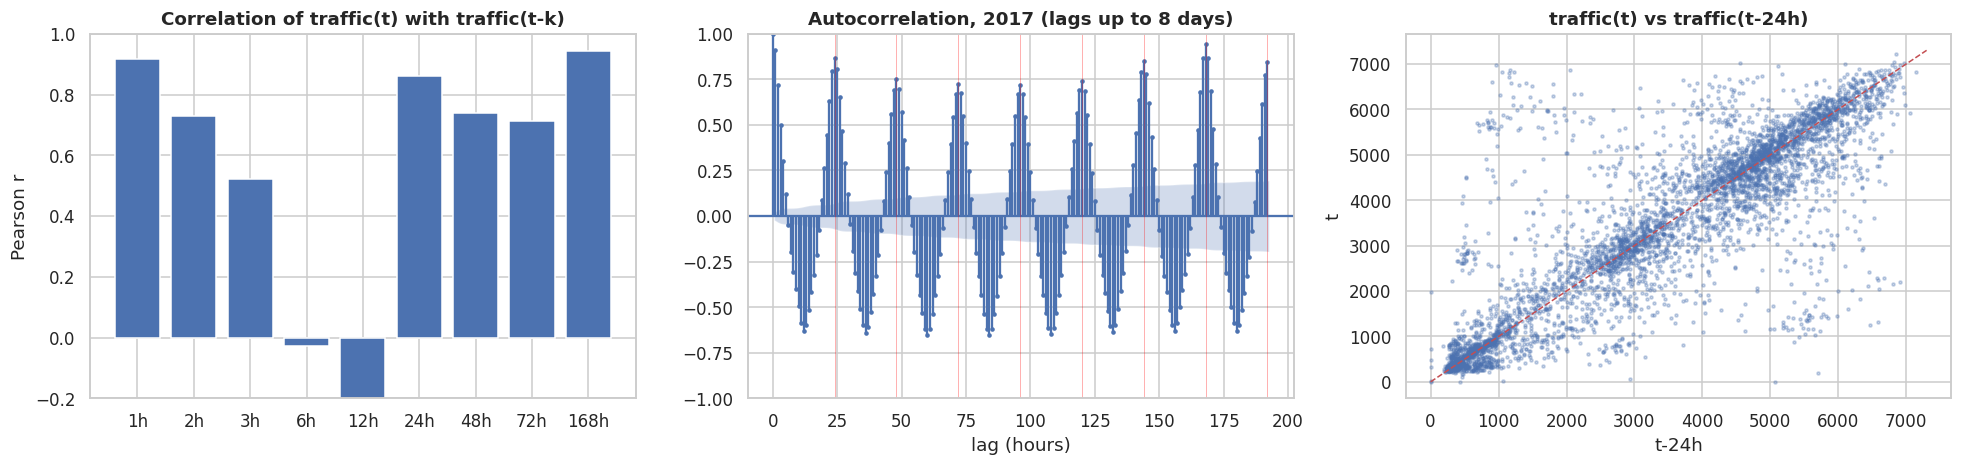

In [12]:
from statsmodels.graphics.tsaplots import plot_acf
series = clean_df[TARGET]
lag_list = [1, 2, 3, 6, 12, 24, 48, 72, 168]
lag_corr = pd.Series({k: series.corr(series.shift(k)) for k in lag_list})
display(lag_corr.round(3).rename("correlation").to_frame())

seg = clean_df.loc["2017-01-01":"2017-12-31", TARGET]
print("Hours missing in 2017 segment used for the ACF:", int(seg.isna().sum()))
fig, axs = plt.subplots(1, 3, figsize=(18, 4.4))
axs[0].bar([f"{k}h" for k in lag_corr.index], lag_corr.values, color=sns.color_palette()[0]); axs[0].set(title="Correlation of traffic(t) with traffic(t-k)", ylim=(-0.2, 1), ylabel="Pearson r")
plot_acf(seg.interpolate(), lags=24 * 8, ax=axs[1], markersize=2); axs[1].set(title="Autocorrelation, 2017 (lags up to 8 days)", xlabel="lag (hours)")
for d in range(1, 9): axs[1].axvline(24 * d, c="red", lw=.5, alpha=.4)
s = pd.concat([series, series.shift(24)], axis=1, keys=["t", "t-24"]).dropna().sample(5000, random_state=0)
axs[2].scatter(s["t-24"], s["t"], s=4, alpha=.3); axs[2].plot([0, 7300], [0, 7300], "r--", lw=1)
axs[2].set(title="traffic(t) vs traffic(t-24h)", xlabel="t-24h", ylabel="t")
plt.tight_layout(); save("q4_lags"); plt.show()

**Interpretation.** Traffic is strongly autocorrelated at three time scales:

* **Short-term momentum:** correlation with the previous hour is 0.92, falling to 0.73 at 2 h and 0.52 at 3 h.
* **Day/night phase:** the correlation turns **negative at 12 h (-0.62)** because 12 hours earlier is the opposite half of the daily cycle (day vs night).
* **Daily and weekly periodicity:** it recovers to **0.86 at 24 h** and peaks at **0.945 at 168 h (one week)**. The weekly lag beats the 24 h lag because the same weekday has the same weekday/weekend behaviour (Q2). The ACF plot shows repeating spikes at every multiple of 24 hours, and the t vs t-24 scatter clusters tightly around the diagonal.

**Implication:** the most useful lag features are **lag_1, lag_24 and lag_168**. The result also explains why "same hour last week" is a surprisingly strong baseline (R2 = 0.89, used as our reference model in Part C).

## Q5. Do moving averages reveal smoother trends and unusual days? (uses moving averages)
*Method:* (a) overlay 24-hour and 7-day moving averages on hourly traffic; (b) compare each complete day's mean with the **trailing** 7-day average of daily means and list the days that deviate most; (c) check how well past moving averages alone track current traffic.

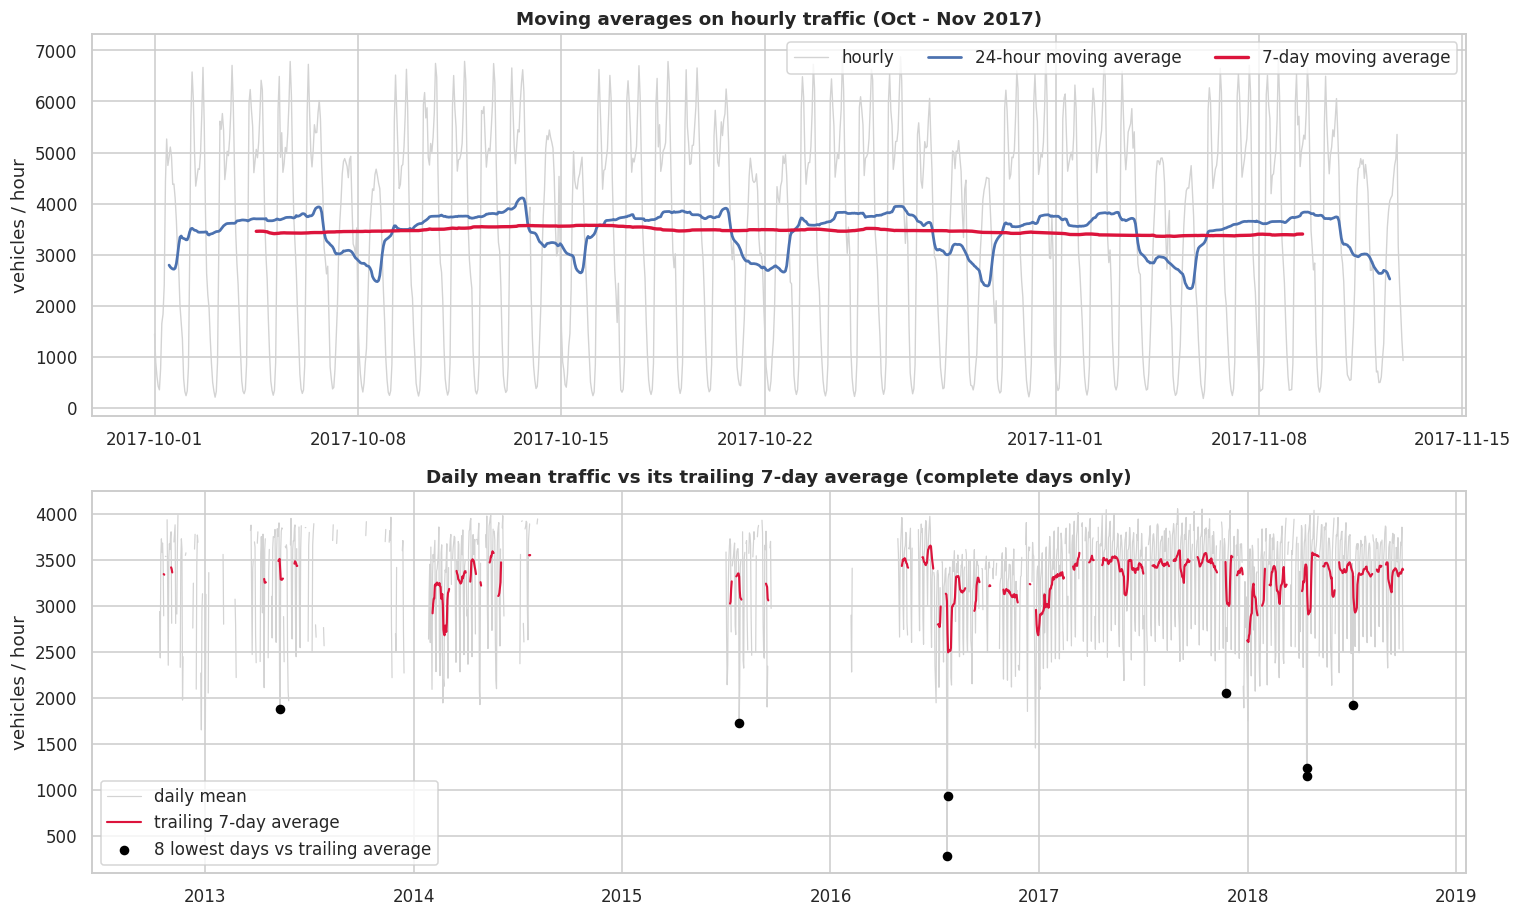

,daily_mean,ratio_to_trailing_7d,weekday,holiday
2016-07-23,277.0,0.09,Sat,
2018-04-14,1144.0,0.33,Sat,
2016-07-24,928.0,0.34,Sun,
2018-04-15,1238.0,0.40,Sun,
2015-07-25,1724.0,0.52,Sat,
2013-05-12,1879.0,0.55,Sun,
2018-07-04,1917.0,0.57,Wed,Independence Day
2017-11-23,2053.0,0.59,Thu,Thanksgiving Day


Correlation of CURRENT traffic with past moving averages: {'3h past mean': np.float64(0.76), '24h past mean': np.float64(0.183), '168h past mean': np.float64(0.087)}


In [13]:
win = clean_df.loc["2017-10-01":"2017-11-12", TARGET]
ma24 = win.rolling(24, center=True).mean(); ma168 = win.rolling(168, center=True).mean()
daily = obs[TARGET].resample("D").agg(["mean", "count"]); daily = daily[daily["count"] == 24]["mean"]
daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max(), freq="D"))
dma7 = daily.rolling(7, min_periods=7).mean().shift(1)           # trailing, past days only
ratio = (daily / dma7).dropna()
low = ratio.nsmallest(8)

fig, axs = plt.subplots(2, 1, figsize=(14, 8.5))
axs[0].plot(win.index, win, c="lightgrey", lw=.9, label="hourly")
axs[0].plot(ma24.index, ma24, c=sns.color_palette()[0], lw=1.8, label="24-hour moving average")
axs[0].plot(ma168.index, ma168, c="crimson", lw=2.2, label="7-day moving average")
axs[0].set(title="Moving averages on hourly traffic (Oct - Nov 2017)", ylabel="vehicles / hour"); axs[0].legend(loc="upper right", ncol=3)
axs[1].plot(daily.index, daily, c="lightgrey", lw=.8, label="daily mean")
axs[1].plot(dma7.index, dma7, c="crimson", lw=1.4, label="trailing 7-day average")
axs[1].scatter(low.index, daily.loc[low.index], c="black", s=28, zorder=5, label="8 lowest days vs trailing average")
axs[1].set(title="Daily mean traffic vs its trailing 7-day average (complete days only)", ylabel="vehicles / hour"); axs[1].legend(loc="lower left")
plt.tight_layout(); save("q5_moving_average"); plt.show()

hol_dates = raw.dropna(subset=["holiday"]).assign(d=lambda x: x.date_time.dt.normalize()).drop_duplicates("d").set_index("d")["holiday"]
tbl = pd.DataFrame({"daily_mean": daily.loc[low.index].round(0), "ratio_to_trailing_7d": low.round(2),
                    "weekday": [DAYS[i.dayofweek] for i in low.index], "holiday": [hol_dates.get(i, "") for i in low.index]})
display(tbl)

f_tmp = add_features(clean_df)
mac = {f"{w}h past mean": f_tmp[[TARGET, f"roll_mean_{w}"]].dropna().corr().iloc[0, 1] for w in ROLL_WINDOWS}
print("Correlation of CURRENT traffic with past moving averages:", {k: round(v, 3) for k, v in mac.items()})

**Interpretation.**

* **Smoothing:** the 24-hour moving average removes the daily cycle but exposes the **weekly cycle** - weekday plateaus around 3,600-4,100 and clear dips on weekends (about 2,400-3,000). The 7-day moving average is almost flat (about 3,400-3,550 in Oct-Nov 2017), confirming the stable level seen in Q1.
* **Unusual days:** comparing each day with its trailing 7-day average flags 2016-07-23 (daily mean 277 vehicles/hour, only 9% of normal), 2016-07-24, 2018-04-14/15 (33-40%) and others. Six of the eight lowest days are weekends, which is partly expected because weekends are naturally about 26% lower (ratio around 0.74); but the most extreme days fall far below that, and two are holidays (4 Jul 2018, Thanksgiving 2017). The data cannot tell us *why* the extreme days are so low (a road closure, an outage at the counter and a major event are all possible), only that they are anomalous.
* **Moving averages as predictors:** the past 3-hour mean correlates 0.76 with current traffic, but the 24-hour mean only 0.18 and the 7-day mean 0.09. Long windows describe the *level*, not the *hour-of-day shape*, so they are weak predictors alone but useful as context alongside hour features (e.g. to recognise a quiet week).

**Implication:** we include 3 h, 24 h and 168 h past-only rolling means (plus a 24 h rolling standard deviation) as features.

## Q6. Does traffic drop on holidays?
*Method:* compare **weekday** rush-hour traffic (07-08 h and 16-17 h) on holidays vs ordinary weekdays (Mann-Whitney U test), and measure each holiday's daily traffic relative to the typical level for that weekday.

Weekday rush-hour mean: holiday = 3,619 (n=200) vs normal = 6,010 (n=4591) -> -39.8%; Mann-Whitney p = 6.6e-73


,mean,count
name,,
New Years Day,-48.2,4
Christmas Day,-47.7,4
Thanksgiving Day,-44.7,4
Independence Day,-39.7,5
Memorial Day,-36.1,5
Labor Day,-29.9,5
Martin Luther King Jr Day,-16.7,3
Washingtons Birthday,-16.3,4
Veterans Day,-5.2,4


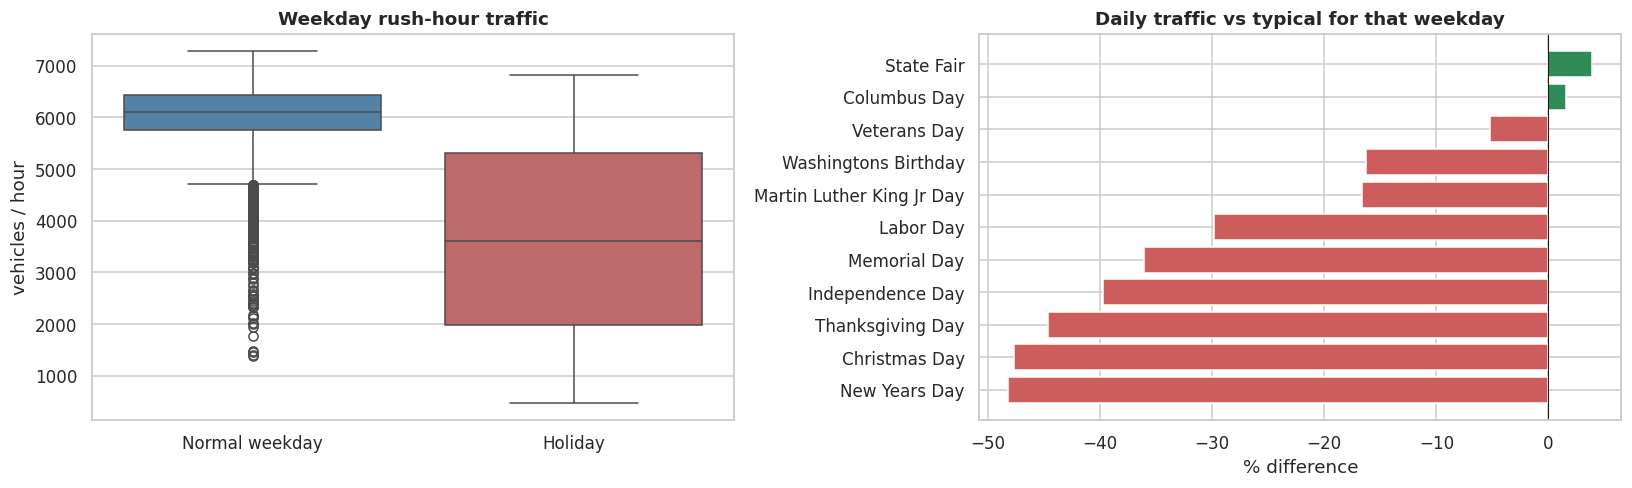

In [14]:
wd = obs[obs.index.dayofweek < 5]
rush = wd[wd.index.hour.isin([7, 8, 16, 17])]
h, nh = rush[rush.is_holiday == 1][TARGET], rush[rush.is_holiday == 0][TARGET]
u = stats.mannwhitneyu(h, nh)
print(f"Weekday rush-hour mean: holiday = {h.mean():,.0f} (n={len(h)}) vs normal = {nh.mean():,.0f} (n={len(nh)}) -> {h.mean()/nh.mean()-1:+.1%}; Mann-Whitney p = {u.pvalue:.2g}")

dd = obs.assign(date=obs.index.normalize())
hd = dd[dd.is_holiday == 1].groupby("date").agg(actual=(TARGET, "mean"), typ=("typical", "mean"), n=(TARGET, "size"))
hd = hd[hd.n >= 20]
hd["name"] = [hol_dates.get(i, "?") for i in hd.index]
hd["pct_vs_typical"] = 100 * (hd.actual / hd.typ - 1)
by_name = hd.groupby("name")["pct_vs_typical"].agg(["mean", "count"]).sort_values("mean")
display(by_name.round(1))

fig, axs = plt.subplots(1, 2, figsize=(15, 4.6))
plot_df = rush.assign(day_type=np.where(rush.is_holiday == 1, "Holiday", "Normal weekday"))
sns.boxplot(data=plot_df, x="day_type", y=TARGET, ax=axs[0], palette=["indianred", "steelblue"][::-1], order=["Normal weekday", "Holiday"])
axs[0].set(title="Weekday rush-hour traffic", xlabel="", ylabel="vehicles / hour")
axs[1].barh(by_name.index, by_name["mean"], color=np.where(by_name["mean"] < 0, "indianred", "seagreen")); axs[1].axvline(0, c="k", lw=.7)
axs[1].set(title="Daily traffic vs typical for that weekday", xlabel="% difference")
plt.tight_layout(); save("q6_holidays"); plt.show()

**Interpretation.** Holidays have a **large and highly significant** effect: weekday rush-hour traffic on holidays averages 3,619 vehicles/hour versus 6,010 on normal weekdays (**-39.8%**, Mann-Whitney p < 1e-70).

The effect is not uniform. Holidays when most people are off - **New Year's Day (-48%), Christmas (-48%), Thanksgiving (-45%), Independence Day (-40%), Memorial Day (-36%), Labor Day (-30%)** - cut daily traffic by a third to a half. Holidays that many employers do not observe - Martin Luther King Jr. Day and Washington's Birthday (about -16%), Veterans Day (-5%), Columbus Day (+2%) - barely change it, and the local **State Fair** (+4%) is not a day off at all. Each holiday has only 3-5 observed days, so individual percentages are indicative rather than precise.

**Implication:** `is_holiday` is a valuable binary feature. A possible refinement, noted for future work, is to distinguish "major" from "minor" holidays.

# Part C - Feature engineering and model training

### C1. Feature engineering
Features are built by `add_features()` in `src/preprocessing.py` on the **hourly grid**, so a lag of 24 is always exactly 24 hours.

| Group | Features | Rationale (from the analysis above) |
|---|---|---|
| Lag features | traffic at t-1, t-2, t-3, t-24, t-48, t-168 | Q4: strong 1 h, 24 h and 168 h autocorrelation |
| Moving averages | mean of the *previous* 3 h, 24 h and 168 h; std of previous 24 h | Q5: capture current level / volatility. Computed from `shift(1)` so the current hour is never included (**no leakage**) |
| Calendar | hour, day-of-week, month as sine/cosine pairs; weekend flag; holiday flag | Q2 and Q6: strong daily/weekly pattern and holiday effect. Cyclical encoding makes 23:00 and 00:00 neighbours |
| Weather | temp, rain_1h, snow_1h, clouds_all, one-hot weather type | Q3: weaker but available (assumes a weather forecast for hour t is known) |

Rows whose lags touch a long gap are dropped rather than imputed.

In [15]:
feat = add_features(clean_df)
model_df = feat.dropna(subset=ALL_FEATURES + [TARGET])
print(f"Usable rows after feature engineering: {len(model_df):,} (from {len(clean_df):,} hourly slots)")
print(f"{len(ALL_FEATURES)} features: {len(WEATHER_FEATURES)} weather + {len(CALENDAR_FEATURES)} calendar + {len(LAG_FEATURES)} lag/rolling")
display(feat.loc["2017-06-05 08:00":"2017-06-05 12:00", [TARGET] + LAG_FEATURES].round(0))

Usable rows after feature engineering: 39,415 (from 52,551 hourly slots)
33 features: 15 weather + 8 calendar + 10 lag/rolling


,traffic_volume,lag_1,lag_2,lag_3,lag_24,lag_48,lag_168,roll_mean_3,roll_mean_24,roll_mean_168,roll_std_24
date_time,,,,,,,,,,,
2017-06-05 08:00:00,6051.0,6187.0,5946.0,3022.0,2387.0,2505.0,1735.0,5052.0,3390.0,3363.0,1646.0
2017-06-05 09:00:00,4737.0,6051.0,6187.0,5946.0,3289.0,3464.0,2371.0,6061.0,3543.0,3388.0,1717.0
2017-06-05 10:00:00,4262.0,4737.0,6051.0,6187.0,3970.0,4248.0,2609.0,5658.0,3603.0,3402.0,1733.0
2017-06-05 11:00:00,4429.0,4262.0,4737.0,6051.0,4327.0,4513.0,3351.0,5017.0,3615.0,3412.0,1737.0
2017-06-05 12:00:00,4478.0,4429.0,4262.0,4737.0,4460.0,4883.0,3504.0,4476.0,3620.0,3419.0,1739.0


### C2. Chronological train / test split
A random split would leak the future into training, so we split **by time**: all real readings before 1 Jan 2018 for training/validation, and Jan - Sep 2018 (never seen during tuning) as the test set. Hyper-parameters are tuned with `TimeSeriesSplit` cross-validation inside the training period only.

In [16]:
SPLIT = "2018-01-01"
train = model_df[(model_df.index < SPLIT) & model_df.observed]
test = model_df[(model_df.index >= SPLIT) & model_df.observed]
print(f"Train: {len(train):,} rows  {train.index.min().date()} -> {train.index.max().date()}")
print(f"Test : {len(test):,} rows  {test.index.min().date()} -> {test.index.max().date()}")
X_tr, y_tr, X_te, y_te = train[ALL_FEATURES], train[TARGET], test[ALL_FEATURES], test[TARGET]

Train: 30,518 rows  2012-10-09 -> 2017-12-31
Test : 6,533 rows  2018-01-01 -> 2018-09-30


### C3. Models and experiments
* **Reference:** seasonal-naive forecast = traffic exactly one week earlier (`lag_168`).
* **Exp 1** Linear Regression (scaled) - simple linear baseline.
* **Exp 2** Random Forest, default settings.
* **Exp 3** XGBoost, default settings.
* **Exp 4** XGBoost with **randomised hyper-parameter search** (20 candidates x 4 time-series folds). *This is our selected model; it is chosen on cross-validation error, not on the test set.*
* **Exp 5** Ablation: Exp 4 hyper-parameters **without** lag / moving-average features, to measure how much those features contribute.

Metrics: RMSE, MAE (vehicles/hour) and R2.

In [17]:
import time
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

tscv = TimeSeriesSplit(n_splits=4, gap=24)
NO_LAG = [c for c in ALL_FEATURES if c not in LAG_FEATURES]
rows = []

def scores(y, p):
    return dict(RMSE=mean_squared_error(y, p) ** .5, MAE=mean_absolute_error(y, p), R2=r2_score(y, p))

def run(exp, name, feats, params, model, cv_rmse=None, fitted=False):
    t = time.time()
    if cv_rmse is None:
        cv_rmse = -cross_val_score(model, train[feats], y_tr, cv=tscv, scoring="neg_root_mean_squared_error").mean()
    if not fitted:
        model.fit(train[feats], y_tr)
    s = scores(y_te, model.predict(test[feats]))
    rows.append({"Exp": exp, "Model": name, "Features": f"{len(feats)} ({'with' if feats is ALL_FEATURES else 'no'} lags)",
                 "Hyper-parameters": params, "CV RMSE": cv_rmse, "Test RMSE": s["RMSE"], "Test MAE": s["MAE"], "Test R2": s["R2"]})
    print(f"{exp}: {name:<28} CV RMSE {cv_rmse:7.1f} | test RMSE {s['RMSE']:7.1f} MAE {s['MAE']:6.1f} R2 {s['R2']:.3f}  ({time.time()-t:.0f}s)")
    return model

# reference: same hour one week earlier
s = scores(y_te, test["lag_168"])
rows.append({"Exp": "Ref", "Model": "Seasonal naive (t-168h)", "Features": "1", "Hyper-parameters": "-", "CV RMSE": np.nan,
             "Test RMSE": s["RMSE"], "Test MAE": s["MAE"], "Test R2": s["R2"]})

m1 = run("Exp 1", "Linear Regression", ALL_FEATURES, "StandardScaler + OLS", make_pipeline(StandardScaler(), LinearRegression()))
m2 = run("Exp 2", "Random Forest (default)", ALL_FEATURES, "n_estimators=100, max_depth=None",
         RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42))
m3 = run("Exp 3", "XGBoost (default)", ALL_FEATURES, "n_estimators=100, max_depth=6, lr=0.3",
         XGBRegressor(random_state=42, n_jobs=-1))

Exp 1: Linear Regression            CV RMSE   413.2 | test RMSE   397.6 MAE  280.1 R2 0.959  (0s)


Exp 2: Random Forest (default)      CV RMSE   279.6 | test RMSE   235.9 MAE  147.5 R2 0.986  (134s)


Exp 3: XGBoost (default)            CV RMSE   278.1 | test RMSE   235.1 MAE  150.4 R2 0.986  (3s)


In [18]:
param_dist = {
    "n_estimators": [150, 250, 350, 500],
    "max_depth": [3, 4, 5, 6, 7],
    "learning_rate": [0.02, 0.05, 0.08, 0.12, 0.2],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.5, 0.7, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 10],
    "reg_lambda": [0.5, 1, 5, 10],
}
t = time.time()
search = RandomizedSearchCV(XGBRegressor(random_state=42, n_jobs=-1), param_dist, n_iter=20, cv=tscv,
                            scoring="neg_root_mean_squared_error", random_state=42, refit=True, n_jobs=1)
search.fit(X_tr, y_tr)
print(f"Search finished in {time.time()-t:.0f}s")
best_params = search.best_params_
print("Best parameters:", best_params)

trials = (pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
          .assign(cv_rmse=lambda d: -d.mean_test_score).sort_values("rank_test_score"))
trials.to_csv(ROOT / "outputs" / "tuning_trials.csv", index=False)
display(trials[["rank_test_score", "cv_rmse", "std_test_score", "params"]].head(5).round(1))

best_model = run("Exp 4", "XGBoost (tuned)", ALL_FEATURES, json.dumps(best_params), search.best_estimator_,
                 cv_rmse=-search.best_score_, fitted=True)
m5 = run("Exp 5", "XGBoost tuned, NO lag feats", NO_LAG, "same as Exp 4", XGBRegressor(random_state=42, n_jobs=-1, **best_params))

Search finished in 93s
Best parameters: {'subsample': 0.6, 'reg_lambda': 0.5, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.7}


,rank_test_score,cv_rmse,std_test_score,params
17,1,261.3,18.7,"{'subsample': 0.6, 'reg_lambda': 0.5, 'n_estim..."
1,2,262.5,18.1,"{'subsample': 1.0, 'reg_lambda': 5, 'n_estimat..."
10,3,262.5,19.6,"{'subsample': 0.6, 'reg_lambda': 1, 'n_estimat..."
19,4,263.3,18.0,"{'subsample': 0.6, 'reg_lambda': 0.5, 'n_estim..."
5,5,263.6,16.9,"{'subsample': 0.8, 'reg_lambda': 0.5, 'n_estim..."


Exp 4: XGBoost (tuned)              CV RMSE   261.3 | test RMSE   222.3 MAE  141.6 R2 0.987  (0s)


Exp 5: XGBoost tuned, NO lag feats  CV RMSE   465.8 | test RMSE   372.7 MAE  228.7 R2 0.964  (6s)


In [19]:
exp_table = pd.DataFrame(rows)
exp_table.to_csv(ROOT / "outputs" / "experiment_table.csv", index=False)
display(exp_table.drop(columns="Hyper-parameters").round({"CV RMSE": 1, "Test RMSE": 1, "Test MAE": 1, "Test R2": 3}).set_index("Exp"))

,Model,Features,CV RMSE,Test RMSE,Test MAE,Test R2
Exp,,,,,,
Ref,Seasonal naive (t-168h),1,NaN,647.2,338.6,0.893
Exp 1,Linear Regression,33 (with lags),413.2,397.6,280.1,0.959
Exp 2,Random Forest (default),33 (with lags),279.6,235.9,147.5,0.986
Exp 3,XGBoost (default),33 (with lags),278.1,235.1,150.4,0.986
Exp 4,XGBoost (tuned),33 (with lags),261.3,222.3,141.6,0.987
Exp 5,"XGBoost tuned, NO lag feats",23 (no lags),465.8,372.7,228.7,0.964


**Interpretation of the experiments.**

* **Baselines.** The seasonal-naive forecast (same hour last week) already reaches R2 = 0.89 (RMSE 647), showing how regular the data is. Linear Regression improves to RMSE 398 (R2 = 0.96) but cannot capture the non-linear daily curve.
* **Tree ensembles.** Random Forest and default XGBoost reach almost identical accuracy (RMSE about 235, **41% lower than Linear Regression**), but XGBoost trains in a few seconds versus over two minutes for Random Forest's cross-validation, so XGBoost was chosen for tuning.
* **Hyper-parameter tuning (Exp 4).** The randomised search lowered cross-validated RMSE from 278.1 to **261.3 (-6%)** and test RMSE from 235.1 to **222.3 (-5.4%)**, with MAE 141.6 and **R2 = 0.987**. The best setting uses 500 shallow-ish trees (depth 6) with a low learning rate (0.05) and row/column sub-sampling (0.6 / 0.7) - a more regularised model than the default. The five best trials all lie between 261 and 264 CV RMSE with a fold-to-fold standard deviation of about 18, so the optimum is a broad plateau rather than a fragile peak.
* **Ablation (Exp 5).** Removing all lag and moving-average features raises RMSE by **68%** (222 -> 373) and cuts R2 to 0.964. The calendar and weather features alone are enough to beat the seasonal-naive baseline, but the autoregressive features are essential for the best accuracy - consistent with the autocorrelation analysis in Q4.
* **CV vs test error.** Test RMSE (222) is lower than CV RMSE (261). We read this as no sign of overfitting; the earliest CV folds train on little and patchier 2012-2015 data, while the 2018 test period is dense and gap-free. The model was selected on CV error, not on the test set.

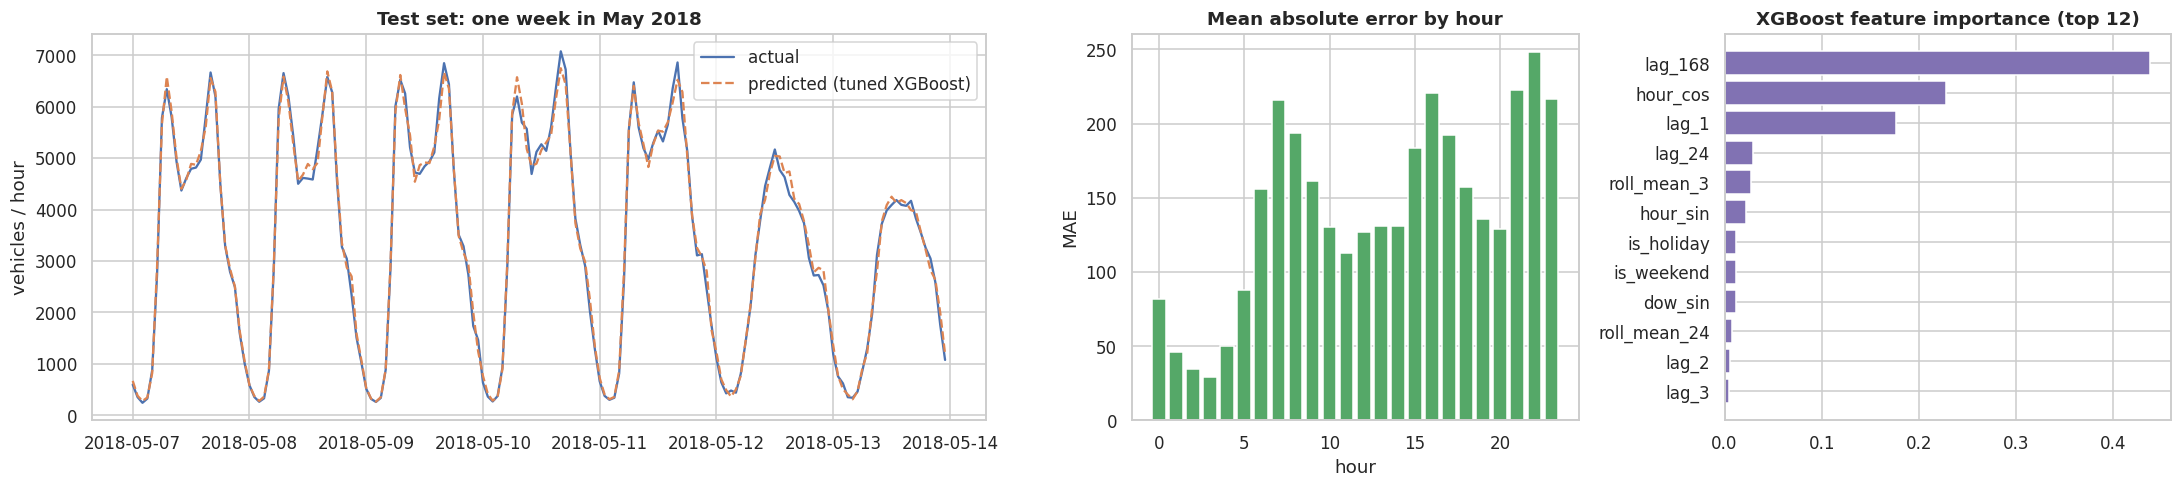

Test MAE 142 | worst hour 22:00 (MAE 248) | best hour 3:00 (MAE 29)
Top features: {'lag_168': 0.43799999356269836, 'hour_cos': 0.2280000001192093, 'lag_1': 0.1770000010728836, 'lag_24': 0.028999999165534973, 'roll_mean_3': 0.027000000700354576, 'hour_sin': 0.02199999988079071}


In [20]:
pred = pd.Series(best_model.predict(X_te), index=X_te.index)
wk = slice("2018-05-07", "2018-05-13 23:00")
res = (y_te - pred)
by_hour = res.abs().groupby(res.index.hour).mean()
imp = pd.Series(best_model.feature_importances_, index=ALL_FEATURES).nlargest(12).sort_values()

fig, axs = plt.subplots(1, 3, figsize=(20, 4.6), gridspec_kw={"width_ratios": [2.2, 1.1, 1.1]})
axs[0].plot(y_te.loc[wk].index, y_te.loc[wk], label="actual"); axs[0].plot(pred.loc[wk].index, pred.loc[wk], "--", label="predicted (tuned XGBoost)")
axs[0].set(title="Test set: one week in May 2018", ylabel="vehicles / hour"); axs[0].legend()
axs[1].bar(by_hour.index, by_hour.values, color=sns.color_palette()[2]); axs[1].set(title="Mean absolute error by hour", xlabel="hour", ylabel="MAE")
axs[2].barh(imp.index, imp.values, color=sns.color_palette()[4]); axs[2].set(title="XGBoost feature importance (top 12)")
plt.tight_layout(); save("c_model_diagnostics"); plt.show()
print(f"Test MAE {res.abs().mean():.0f} | worst hour {by_hour.idxmax()}:00 (MAE {by_hour.max():.0f}) | best hour {by_hour.idxmin()}:00 (MAE {by_hour.min():.0f})")
print("Top features:", imp.sort_values(ascending=False).round(3).head(6).to_dict())

**Interpretation.** The tuned model follows both the weekday double peak and the lower weekend profile closely. The average error of **142 vehicles/hour is about 4% of the mean hourly volume**. Errors are smallest at night (MAE 29 at 03:00, when traffic is low and predictable) and largest at **22:00 (MAE 248)**, during the steep evening decline when small timing shifts matter most.

Feature importance confirms the EDA: **lag_168 (0.44), hour_cos (0.23) and lag_1 (0.18)** together carry about 84% of the importance - weekly pattern, time of day and the previous hour - while none of the weather variables appear in the top six.

**Limitations (to state in the report):** (1) the model uses the weather *at* hour t as an input, so deployment needs a weather forecast; (2) it forecasts one hour ahead - multi-step forecasts would need recursive prediction; (3) rows next to the 2014-15 outage cannot be used; (4) `is_holiday` treats all holidays equally.

### C4. Save the trained model for Task 4

In [21]:
import joblib
(ROOT / "models").mkdir(exist_ok=True)
joblib.dump(best_model, ROOT / "models" / "xgb_traffic_model.joblib")
final = exp_table[exp_table.Exp == "Exp 4"].iloc[0]
meta = {
    "target": TARGET, "model": "XGBRegressor (tuned)", "features": ALL_FEATURES, "best_params": best_params,
    "train_range": [str(train.index.min()), str(train.index.max())], "test_range": [str(test.index.min()), str(test.index.max())],
    "test_metrics": {"RMSE": round(final["Test RMSE"], 1), "MAE": round(final["Test MAE"], 1), "R2": round(final["Test R2"], 4)},
    "preprocessing": {"max_interp_hours": MAX_INTERP_HOURS, "lags": LAGS, "rolling_windows": ROLL_WINDOWS,
                      "temp_min_k": TEMP_MIN_K, "rain_max_mm": RAIN_MAX_MM},
}
(ROOT / "models" / "model_metadata.json").write_text(json.dumps(meta, indent=2))
clean_df.reset_index().to_csv(ROOT / "data" / "processed" / "traffic_hourly_clean.csv", index=False)
print("Saved model, metadata and cleaned hourly data.")

Saved model, metadata and cleaned hourly data.


### Summary and hand-over to Tasks 2-4

| Output | Location | Used in |
|---|---|---|
| Cleaned hourly dataset (52,551 rows incl. imputation flag) | `data/processed/traffic_hourly_clean.csv` | Task 2 (load into MySQL and MongoDB) |
| Reusable preprocessing / feature code | `src/preprocessing.py` | Task 4 (same pipeline at inference) |
| Trained tuned-XGBoost model | `models/xgb_traffic_model.joblib` | Task 4 |
| Feature list, parameters, metrics | `models/model_metadata.json` | Task 4 |
| Experiment table and tuning trials | `outputs/experiment_table.csv`, `outputs/tuning_trials.csv` | Report |
| Figures | `outputs/figures/` | Report |

**Headline results:** 22.8% of hours are missing (mostly one 10-month outage); there is no long-term trend; traffic is governed by hour-of-day, day-of-week and holidays; weather is a minor factor; and a tuned XGBoost with lag and moving-average features reaches **RMSE 222 vehicles/hour (R2 = 0.987)** on the unseen 2018 test period, versus 647 for the seasonal-naive reference.